In [1]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as fit
from scipy.signal import periodogram
sys.path.append("../")
from analysis import System

def wave(t, A, phi, offset):
    return np.abs(A) * np.sin(109e3 * 2 * np.pi * t - phi) + offset
def interference(x, A, offset):
    return np.abs(A) * np.power(np.cos(x * np.pi / 2 / 1064e-9), 2) + offset
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

There are 2 data sets. The first one I found to be a bit questionable, but the second consists of the same kinds of traces along with calibration traces. I'll investigate which of these proves better below.

1V piezo stroke distance:	0.25325739573854233 +/- 0.12397747653333356
2V piezo stroke distance:	0.46956207669734196 +/- 0.2017172786673261
3V piezo stroke distance:	0.6813924613674018 +/- 0.26989949480080516
4V piezo stroke distance:	0.9321586132112344 +/- 0.4335477635653158
5V piezo stroke distance:	1.2356665007673002 +/- 0.48300877937771297
5.5V piezo stroke distance:	0.9226983099721437 +/- 0.42632272802475113
6V piezo stroke distance:	0.7230097944021694 +/- 0.316094896153063
6.5V piezo stroke distance:	1.0748986897393096 +/- 0.35443012087367665
7V piezo stroke distance:	1.4088618577284975 +/- 0.617234720562062
7.5V piezo stroke distance:	1.0865225329516377 +/- 0.38693148426462237
8V piezo stroke distance:	0.7155400515924228 +/- 0.15232649891493422
8.5V piezo stroke distance:	1.9605277922732924 +/- 0.870311378586505
9V piezo stroke distance:	0.7965951734460901 +/- 0.1406555918369122
9.5V piezo stroke distance:	0.7892790325628496 +/- 0.23932797734179379
10V piezo stroke distance:	1.11

<ErrorbarContainer object of 3 artists>

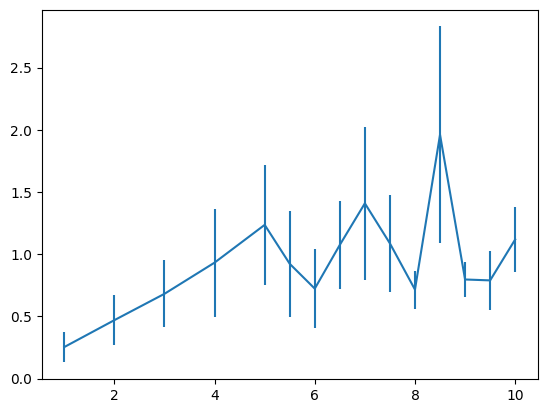

In [95]:
voltages = ["1", "2", "3", "4", "5", "5.5", "6", "6.5", "7", "7.5", "8", "8.5", "9", "9.5", "10"]
l = System("michelson", ["../../data/20261006/1st/piezo_char_" + j + "V_109kHz/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 20)], set_data = True, channel = "X")
def x(V):
    return (2 * 1064 / np.pi) * np.arccos(np.sqrt(np.abs(V - 0.95) / 1.66))
y = []
stds = []
for v in range(len(voltages)):
    disps = []
    for i in range(20 * v, 20 * (v + 1)):
        v1 = np.mean(l.get_data()[i].collection[0].x)
        v2 = np.mean(l.get_data()[i].collection[1].x)
        l.get_data()[i].apply("detrend", mode = "linear", inplace = True)
        f, p1 = periodogram(l.get_data()[i].collection[0].x, l.get_data()[i].r)
        fit1, _ = fit(wave, l.get_data()[i].collection[0].t, l.get_data()[i].collection[0].x, p0 = [0.01, 0, 0])
        _, p2 = periodogram(l.get_data()[i].collection[1].x, l.get_data()[i].r)
        fit2, _ = fit(wave, l.get_data()[i].collection[1].t, l.get_data()[i].collection[1].x, p0 = [0.01, 0, 0])
        disp1 = np.abs(fit1[0])
        disp2 = np.abs(fit2[0])
        disp = ((x(v1 - disp1) - x(v1 + disp1)) + (x(v2 - disp2) - x(v2 + disp2))) / 2
        disps.append(disp)
    print(f"{voltages[v]}V piezo stroke distance:\t{np.mean(disps)} +/- {np.std(disps)}")
    y.append(np.mean(disps))
    stds.append(np.std(disps))
plt.errorbar(np.array(voltages, dtype = float), y, yerr = stds)

1V piezo stroke distance:	0.47710361535883694 +/- 0.43021056578616
2V piezo stroke distance:	0.7127745992803284 +/- 0.6063241260320549
3V piezo stroke distance:	0.9009636984481716 +/- 0.3479340028923275
4V piezo stroke distance:	1.5307228600891947 +/- 0.734031877562448
5V piezo stroke distance:	0.7658953783339839 +/- 0.30227775560617276
5.5V piezo stroke distance:	2.021079122573184 +/- 1.0232748749292848
6V piezo stroke distance:	1.5886827850542757 +/- 1.1121926734842784
6.5V piezo stroke distance:	1.3649697964298682 +/- 0.6489622196704944
7V piezo stroke distance:	1.6186780201727102 +/- 1.120623669904023
7.5V piezo stroke distance:	1.5500052515815768 +/- 0.7757297106032716
8V piezo stroke distance:	1.8801932392271952 +/- 1.304119480031999
8.5V piezo stroke distance:	1.774053810261202 +/- 0.9714724527091139
9V piezo stroke distance:	1.7475392002527912 +/- 1.0505872237559195
9.5V piezo stroke distance:	1.9187129381790342 +/- 0.9126885120895746
10V piezo stroke distance:	2.44101933750105

<ErrorbarContainer object of 3 artists>

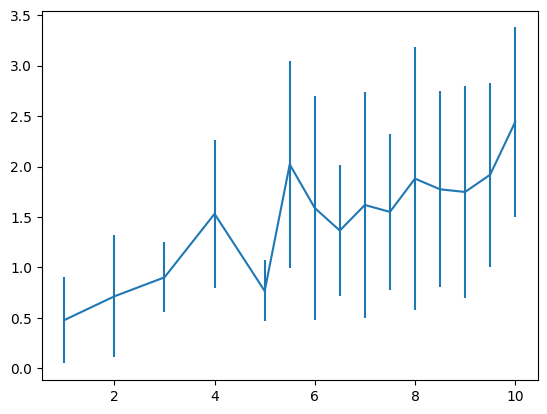

In [94]:
voltages = ["1", "2", "3", "4", "5", "5.5", "6", "6.5", "7", "7.5", "8", "8.5", "9", "9.5", "10"]
l = System("michelson", ["../../data/20261006/2nd/piezo_char_" + j + "V_109kHz_real/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 20)], set_data = True, channel = "X")
def x(V):
    return (2 * 1064 / np.pi) * np.arccos(np.sqrt(np.abs(V - 0.95) / 1.66))
y = []
stds = []
for v in range(len(voltages)):
    disps = []
    for i in range(20 * v, 20 * (v + 1)):
        v1 = np.mean(l.get_data()[i].collection[0].x)
        v2 = np.mean(l.get_data()[i].collection[1].x)
        l.get_data()[i].apply("detrend", mode = "linear", inplace = True)
        f, p1 = periodogram(l.get_data()[i].collection[0].x, l.get_data()[i].r)
        fit1, _ = fit(wave, l.get_data()[i].collection[0].t, l.get_data()[i].collection[0].x, p0 = [0.01, 0, 0])
        _, p2 = periodogram(l.get_data()[i].collection[1].x, l.get_data()[i].r)
        fit2, _ = fit(wave, l.get_data()[i].collection[1].t, l.get_data()[i].collection[1].x, p0 = [0.01, 0, 0])
        disp1 = np.abs(fit1[0])
        disp2 = np.abs(fit2[0])
        disp = np.abs(((x(v1 - disp1) - x(v1 + disp1)) + (x(v2 - disp2) - x(v2 + disp2))) / 2)
        disps.append(disp)
    print(f"{voltages[v]}V piezo stroke distance:\t{np.mean(disps)} +/- {np.std(disps)}")
    y.append(np.mean(disps))
    stds.append(np.std(disps))
plt.errorbar(np.array(voltages, dtype = float), y, yerr = stds)

1V piezo stroke distance:	0.2611358042586289 +/- 0.07287113227794652
2V piezo stroke distance:	0.5268644988107638 +/- 0.11389014789039523
3V piezo stroke distance:	0.48875015855278436 +/- 0.19285291697150722
4V piezo stroke distance:	1.0434175136260309 +/- 0.2521727061655394
5V piezo stroke distance:	0.4400168780056717 +/- 0.1896728421871034
5.5V piezo stroke distance:	0.9136020744168093 +/- 0.30024582500053837
6V piezo stroke distance:	0.778933791759934 +/- 0.41636522734198284
6.5V piezo stroke distance:	0.8251633810997433 +/- 0.4014121603063954
7V piezo stroke distance:	1.1984148578572742 +/- 0.2833916097299034
7.5V piezo stroke distance:	0.8913963455015477 +/- 0.4319766592923541
8V piezo stroke distance:	1.3290323378474114 +/- 0.6784449708924991
8.5V piezo stroke distance:	0.9418173956978635 +/- 0.38042329804458014
9V piezo stroke distance:	1.1671059622098354 +/- 0.32618066801081974
9.5V piezo stroke distance:	1.0696677276487379 +/- 0.40361081794966835
10V piezo stroke distance:	1.7

<ErrorbarContainer object of 3 artists>

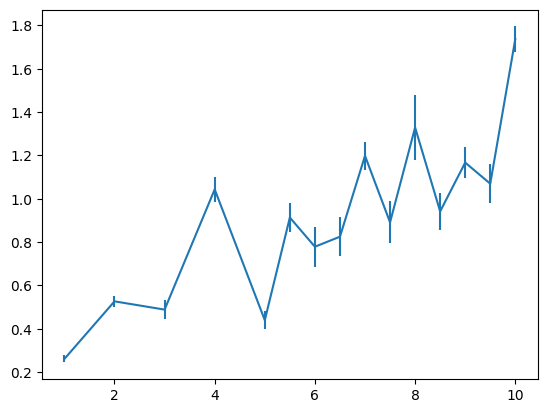

In [6]:
voltages = ["1", "2", "3", "4", "5", "5.5", "6", "6.5", "7", "7.5", "8", "8.5", "9", "9.5", "10"]
l = System("michelson", ["../../data/20261006/2nd/piezo_char_" + j + "V_109kHz_real/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 20)], set_data = True, channel = "X")
cals = System("michelson", ["../../data/20261006/2nd/piezo_char_" + j + "V_109kHz_calibration/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 3)], set_data = True, channel = "X")
def x(V, A, mn):
    return (2 * 1064 / np.pi) * np.arccos(np.sqrt(np.abs(V - mn) / A))
y = []
stds = []
for v in range(len(voltages)):
    mx = max(cals.get_data()[0].collection[0].x)
    mn = min(cals.get_data()[0].collection[0].x)
    for i in range(3 * v, 3 * (v + 1)):
        if mx < max(cals.get_data()[i].collection[0].x):
            mx = max(cals.get_data()[i].collection[0].x)
        if mx < max(cals.get_data()[i].collection[1].x):
            mx = max(cals.get_data()[i].collection[1].x)
        if mn > min(cals.get_data()[i].collection[0].x):
            mn = min(cals.get_data()[i].collection[0].x)
        if mn > min(cals.get_data()[i].collection[1].x):
            mn = min(cals.get_data()[i].collection[1].x)
    disps = []
    A = mx - mn
    for i in range(20 * v, 20 * (v + 1)):
        v1 = np.mean(l.get_data()[i].collection[0].x)
        v2 = np.mean(l.get_data()[i].collection[1].x)
        l.get_data()[i].apply("detrend", mode = "linear", inplace = True)
        fit1, _ = fit(wave, l.get_data()[i].collection[0].t, l.get_data()[i].collection[0].x, p0 = [0.01, 0, 0])
        fit2, _ = fit(wave, l.get_data()[i].collection[1].t, l.get_data()[i].collection[1].x, p0 = [0.01, 0, 0])
        disp1 = np.abs(fit1[0])
        disp2 = np.abs(fit2[0])
        disp = np.abs(((x(v1 - disp1, A, mn) - x(v1 + disp1, A, mn)) + (x(v2 - disp2, A, mn) - x(v2 + disp2, A, mn))) / 2)
        disps.append(disp)
    print(f"{voltages[v]}V piezo stroke distance:\t{np.mean(disps)} +/- {np.std(disps)}")
    y.append(np.mean(disps))
    stds.append(np.std(disps))
plt.errorbar(np.array(voltages, dtype = float), y, yerr = stds)

1V piezo stroke distance:	0.251502413708765 +/- 0.08317039656479831
2V piezo stroke distance:	0.46045367501749296 +/- 0.12084601290198622
3V piezo stroke distance:	0.3638323459212174 +/- 0.1614250922964671
4V piezo stroke distance:	0.738339038034502 +/- 0.19023278053674514
5V piezo stroke distance:	0.3528131473345638 +/- 0.15659210263716486
5.5V piezo stroke distance:	0.6489072150939691 +/- 0.18477311310848585
6V piezo stroke distance:	0.6419571339015206 +/- 0.24472134363471396
6.5V piezo stroke distance:	0.5983894838283547 +/- 0.291184626315779
7V piezo stroke distance:	0.8979254612009797 +/- 0.20475265624561353
7.5V piezo stroke distance:	0.6849325295720832 +/- 0.33252051842407393
8V piezo stroke distance:	0.9652825539681842 +/- 0.4731063608552767
8.5V piezo stroke distance:	0.7637540647952505 +/- 0.2750515460159707
9V piezo stroke distance:	0.8086611984409231 +/- 0.20094239851259948
9.5V piezo stroke distance:	0.810436988885509 +/- 0.24807388609873002
10V piezo stroke distance:	1.15

<ErrorbarContainer object of 3 artists>

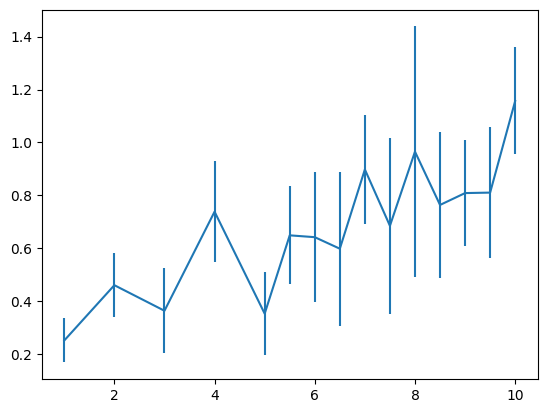

In [12]:
voltages = ["1", "2", "3", "4", "5", "5.5", "6", "6.5", "7", "7.5", "8", "8.5", "9", "9.5", "10"]
l = System("michelson", ["../../data/20261006/2nd/piezo_char_" + j + "V_109kHz_real/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 20)], set_data = True, channel = "X")
cals = System("michelson", ["../../data/20261006/2nd/piezo_char_" + j + "V_109kHz_calibration/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 3)], set_data = True, channel = "X")
def x(V, A, mn):
    return (2 * 1064 / np.pi) * np.arccos(np.sqrt(np.abs(V - mn) / A))
y = []
stds = []
for v in range(len(voltages)):
    mx = max(cals.get_data()[0].collection[0].x)
    mn = min(cals.get_data()[0].collection[0].x)
    for i in range(3 * v, 3 * (v + 1)):
        if mx < max(cals.get_data()[i].collection[0].x):
            mx = max(cals.get_data()[i].collection[0].x)
        if mx < max(cals.get_data()[i].collection[1].x):
            mx = max(cals.get_data()[i].collection[1].x)
        if mn > min(cals.get_data()[i].collection[0].x):
            mn = min(cals.get_data()[i].collection[0].x)
        if mn > min(cals.get_data()[i].collection[1].x):
            mn = min(cals.get_data()[i].collection[1].x)
    disps = []
    A = mx - mn
    for i in range(20 * v, 20 * (v + 1)):
        l.get_data()[i].apply("time_gate", tmin = 0, tmax = 5e-5, inplace = True)
        v1 = np.mean(l.get_data()[i].collection[0].x)
        v2 = np.mean(l.get_data()[i].collection[1].x)
        l.get_data()[i].apply("detrend", mode = "linear", inplace = True)
        f, p1 = periodogram(l.get_data()[i].collection[0].x, l.get_data()[i].r)
        idx_freq = find_idx(f, find_nearest(f, 1.09e5))
        delf = f[1] - f[0]
        disp1 = np.sqrt(2 * p1[idx_freq] * delf)
        _, p2 = periodogram(l.get_data()[i].collection[1].x, l.get_data()[i].r)
        disp2 = np.sqrt(2 * p2[idx_freq] * delf)
        disp = np.abs(((x(v1 - disp1, A, mn) - x(v1 + disp1, A, mn)) + (x(v2 - disp2, A, mn) - x(v2 + disp2, A, mn))) / 2)
        disps.append(disp)
    print(f"{voltages[v]}V piezo stroke distance:\t{np.mean(disps)} +/- {np.std(disps)}")
    y.append(np.mean(disps))
    stds.append(np.std(disps))
plt.errorbar(np.array(voltages, dtype = float), y, yerr = stds)

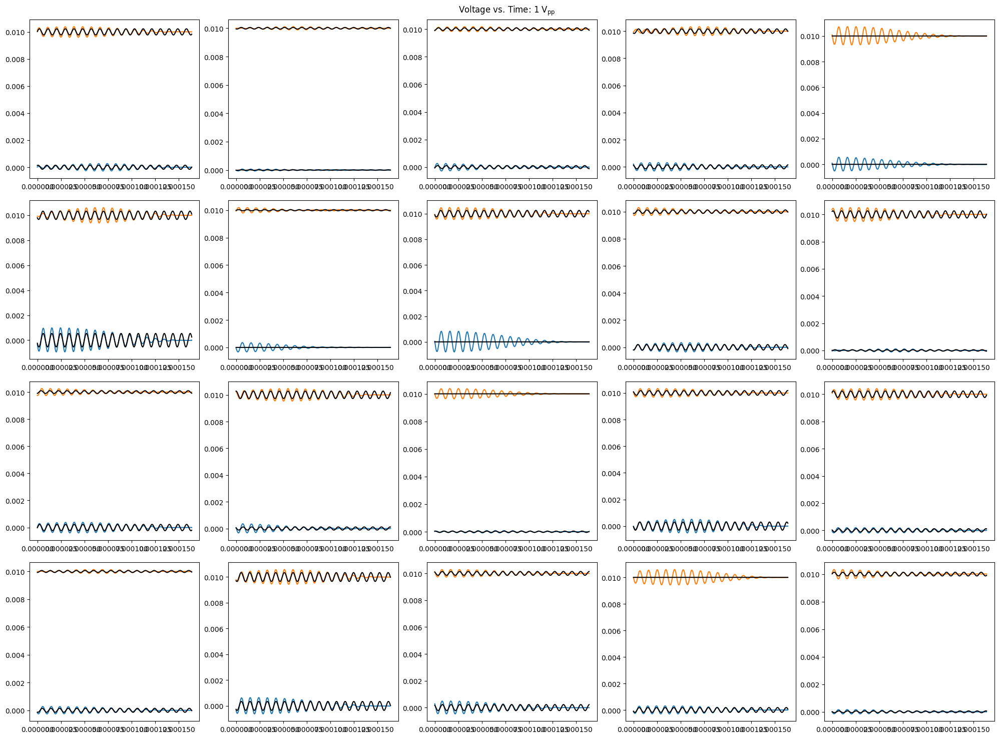

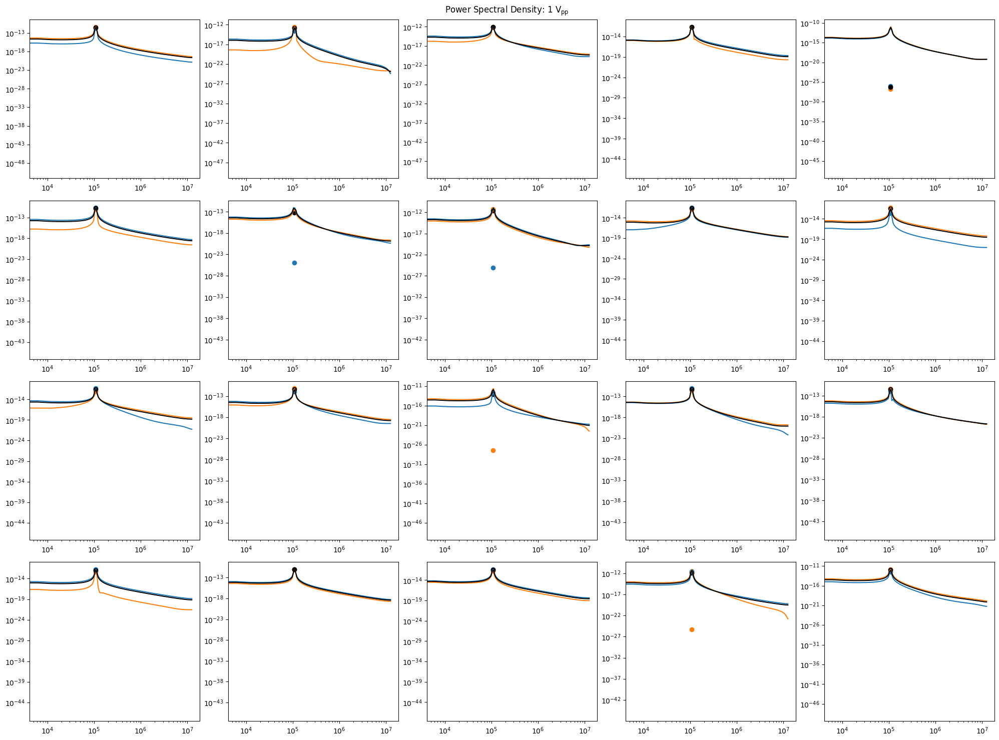

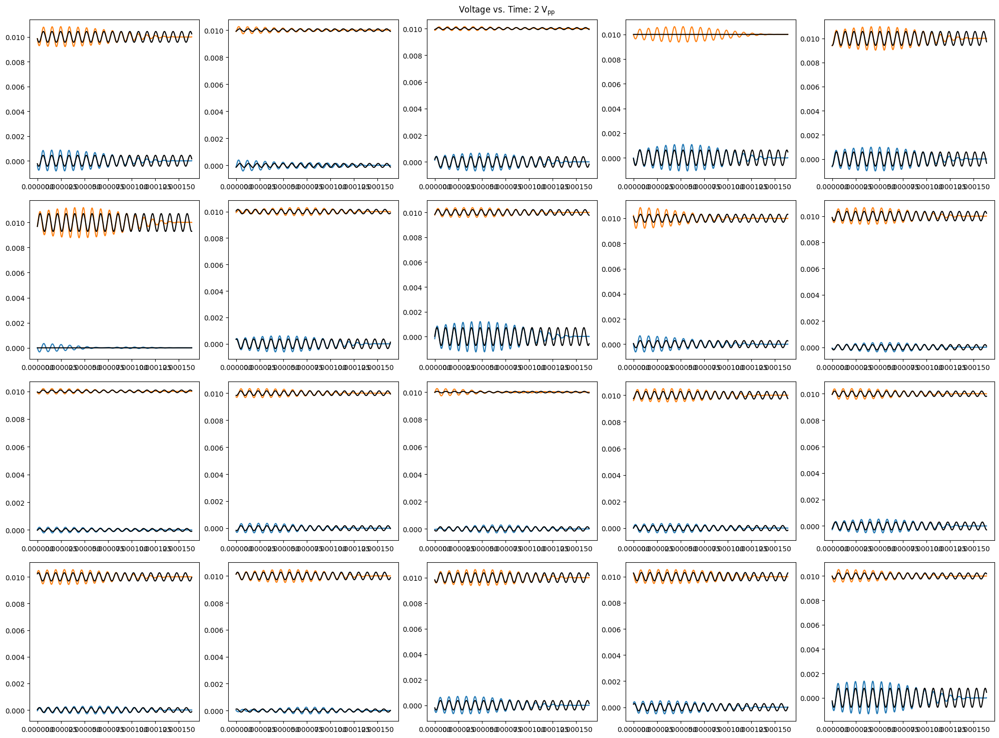

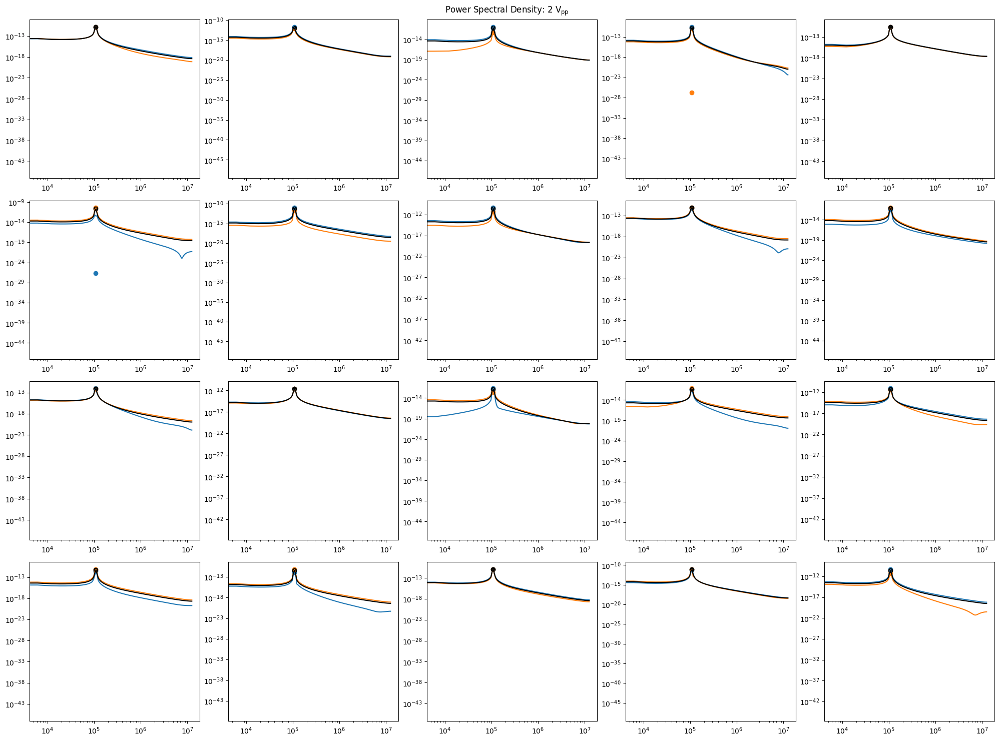

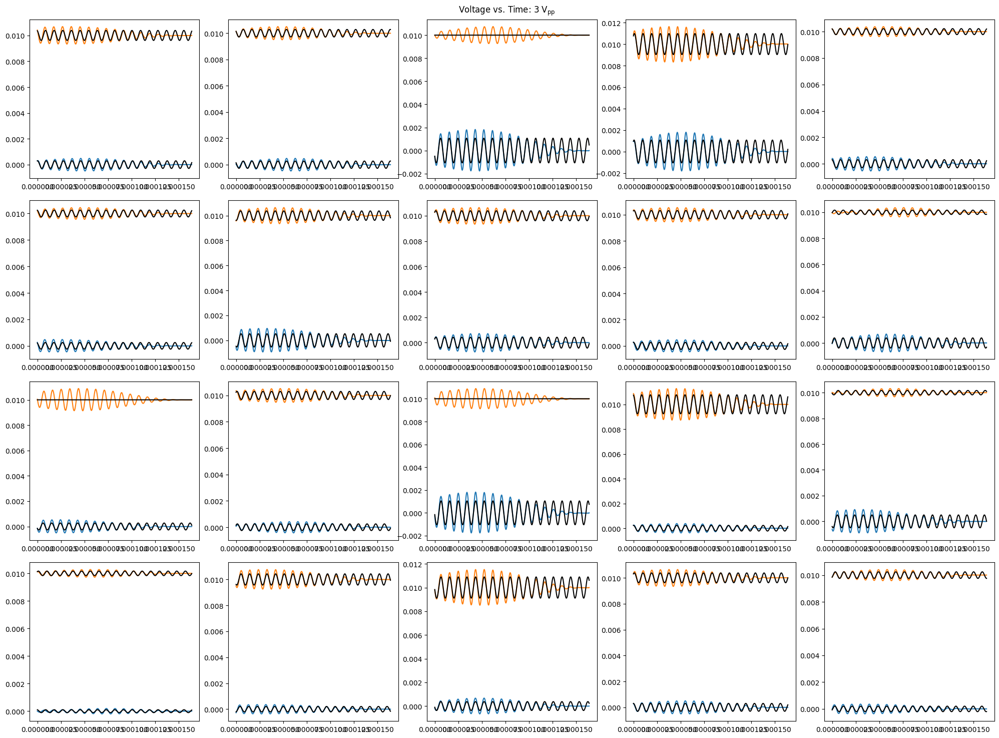

...

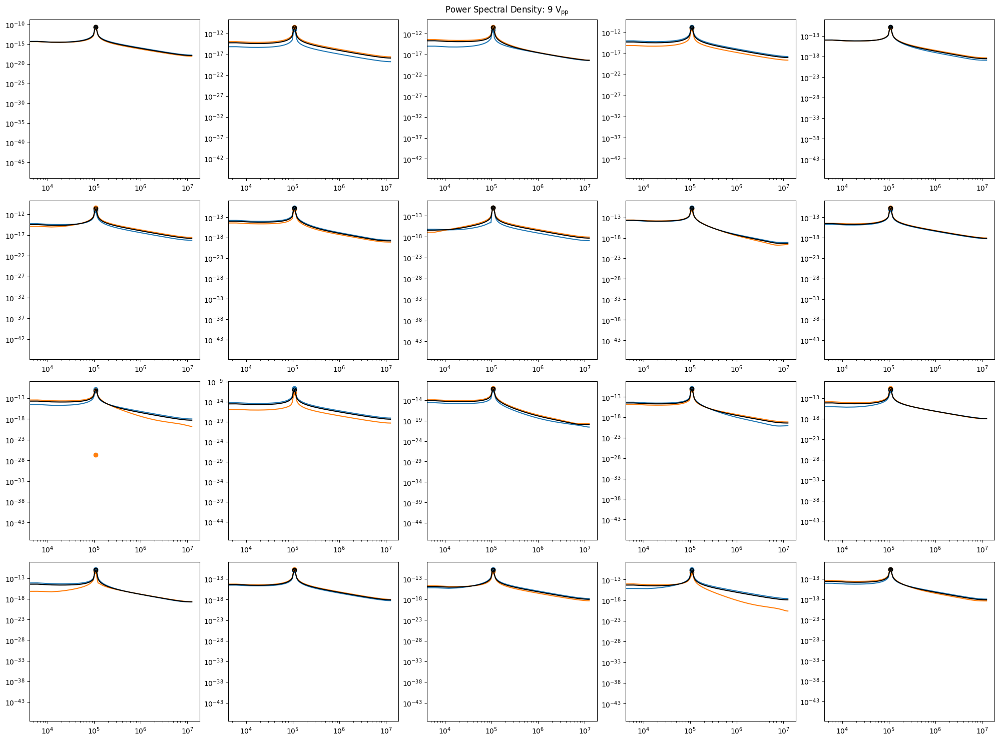

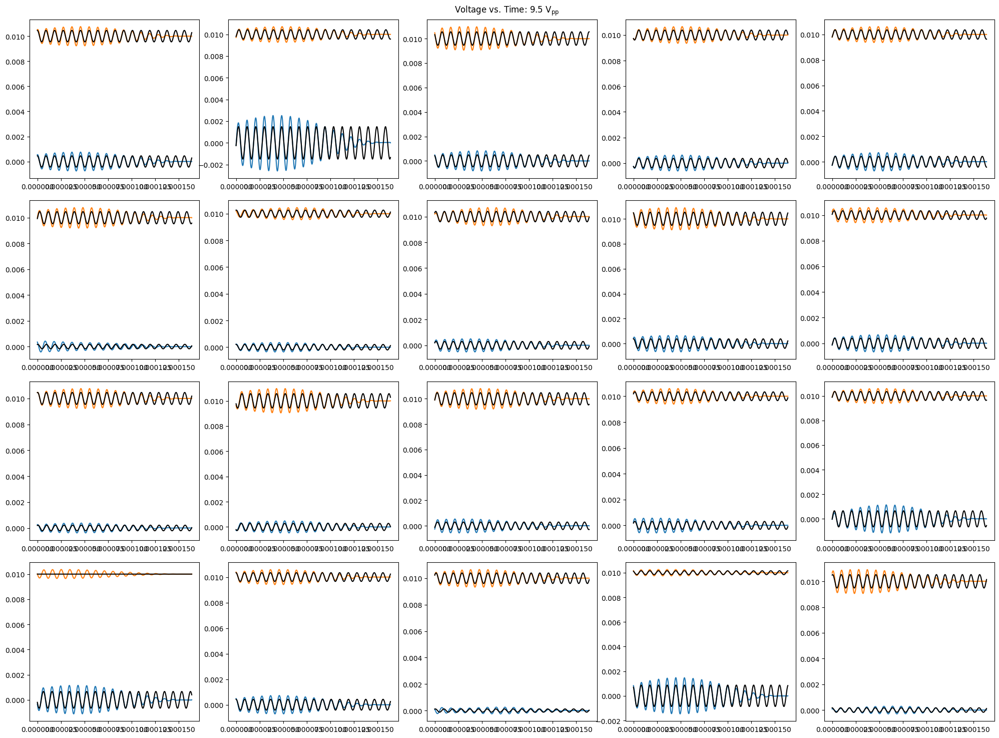

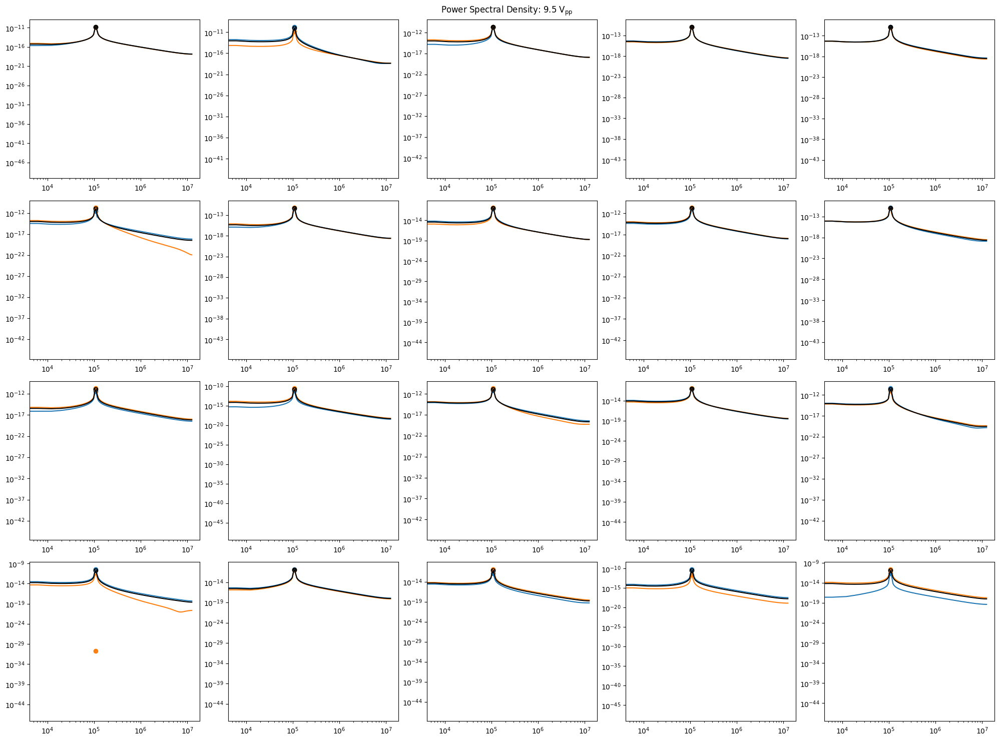

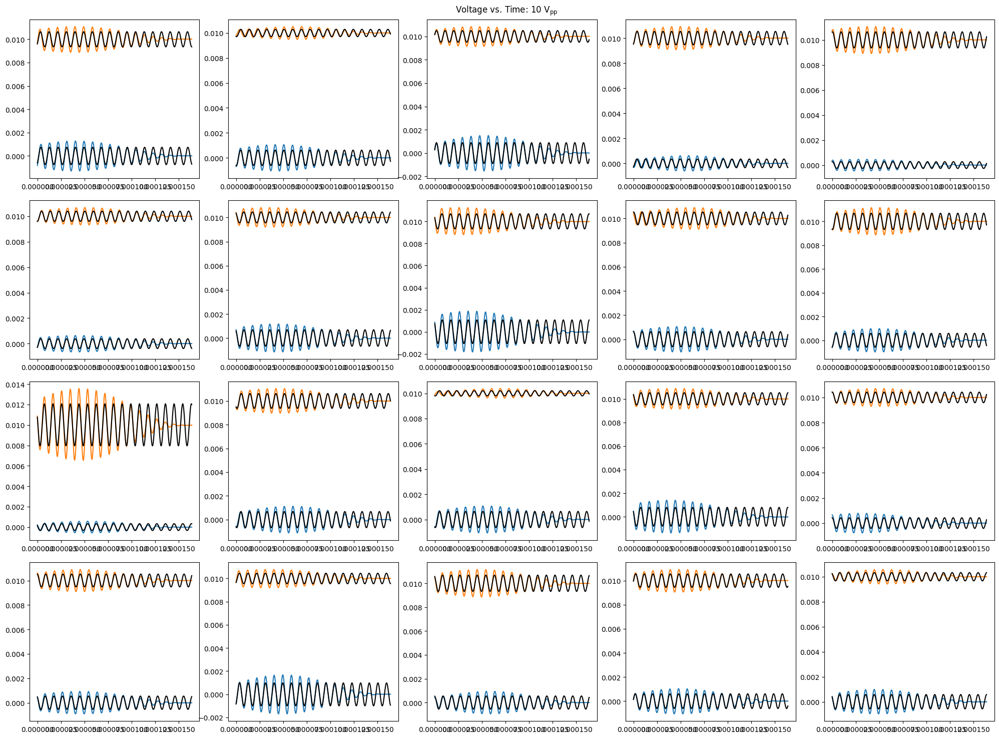

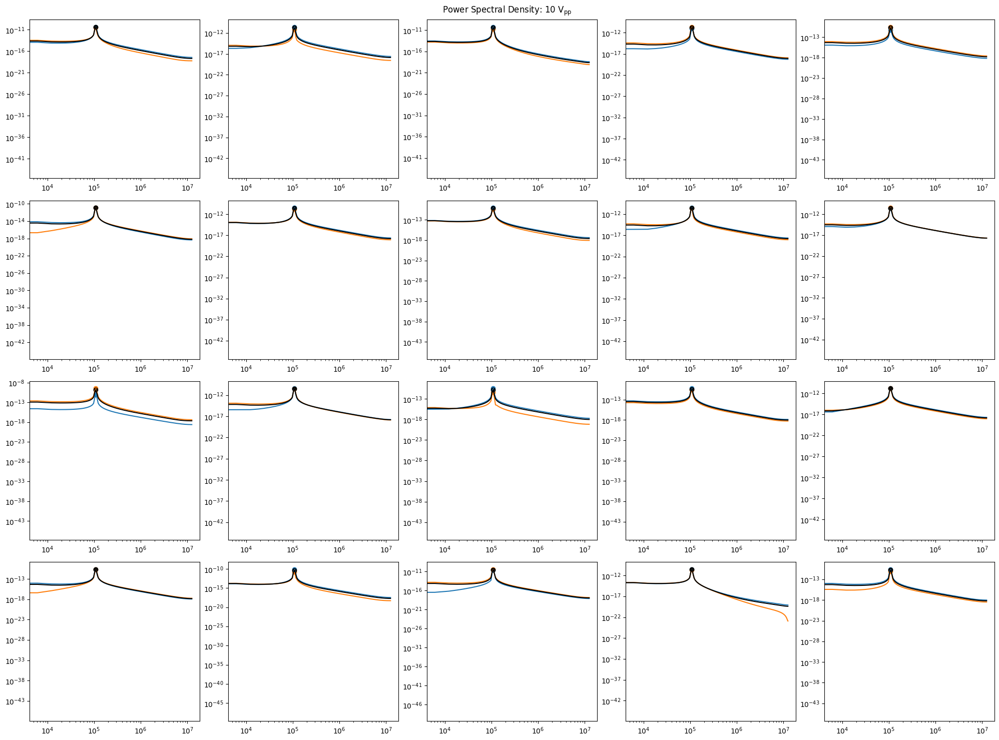

In [88]:
voltages = ["1", "2", "3", "4", "5", "5.5", "6", "6.5", "7", "7.5", "8", "8.5", "9", "9.5", "10"]
l = System("michelson", ["../../data/20261006/2nd/piezo_char_" + j + "V_109kHz_real/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 20)], set_data = True, channel = "X")
cals = System("michelson", ["../../data/20261006/2nd/piezo_char_" + j + "V_109kHz_calibration/iter_" + str(i) + ".tdms" for j in voltages for i in range(0, 3)], set_data = True, channel = "X")
freq = 109e3
calc_psds = []
data_psds = []
amps = []
As = []
Vs = []
Vmaxes = []
Vmins = []
for c in range(len(voltages)):
    mx = max(cals.get_data()[0].collection[0].x)
    mn = min(cals.get_data()[0].collection[0].x)
    for i in range(3 * c, 3 * (c + 1)):
        if mx < max(cals.get_data()[i].collection[0].x):
            mx = max(cals.get_data()[i].collection[0].x)
        if mx < max(cals.get_data()[i].collection[1].x):
            mx = max(cals.get_data()[i].collection[1].x)
        if mn > min(cals.get_data()[i].collection[0].x):
            mn = min(cals.get_data()[i].collection[0].x)
        if mn > min(cals.get_data()[i].collection[1].x):
            mn = min(cals.get_data()[i].collection[1].x)
    A = mx - mn
    As.append(A)
    Vmins.append(mn)
    Vmaxes.append(mx)
    cpsd = []
    dpsd = []
    amp = []
    V = []
    fig1, ax1 = plt.subplots(4, 5, figsize = (20, 15))
    fig1.suptitle(rf"Voltage vs. Time: {voltages[c]} V$_{{\text{{pp}}}}$")
    plt.tight_layout()
    fig2, ax2 = plt.subplots(4, 5, figsize = (20, 15))
    fig2.suptitle(rf"Power Spectral Density: {voltages[c]} V$_{{\text{{pp}}}}$")
    plt.tight_layout()

    piezo = System("michelson", [f"../../data/20261006/1st/piezo_char_{voltages[c]}V_109kHz/iter_{str(i)}.tdms" for i in range(0, 20)], set_data = True, channel = "X")

    for i, d in enumerate(piezo.get_data()):
        sig = 0
        r = d.r
        tmax = 2e-5
        tmin = d.collection[0].t[find_idx(d.collection[0].t, find_nearest(d.collection[0].t, (d.collection[0].t[-1] - tmax) * np.random.default_rng().random())) - 1]
        # d.apply("time_gate", tmin = tmin, tmax = tmin + tmax, inplace = True)
        d.apply("filter", cutoff = [104e3, 114e3], btype = "bandpass", inplace = True)
        v1 = np.mean(d.collection[0].x)
        v2 = np.mean(d.collection[1].x)
        d.apply("detrend", mode = "linear", inplace = True)
        ax1[i // 5][i % 5].plot(d.collection[0].t, d.collection[0].x)
        d1, _ = fit(wave, d.collection[0].t, d.collection[0].x, p0 = [0.005, 0, 0])
        ax1[i // 5][i % 5].plot(d.collection[0].t, wave(d.collection[0].t, *d1), c = "k")
        ax1[i // 5][i % 5].plot(d.collection[1].t, d.collection[1].x + 0.01)
        d2, _ = fit(wave, d.collection[1].t, d.collection[1].x, p0 = [0.005, 0, 0])
        ax1[i // 5][i % 5].plot(d.collection[1].t, wave(d.collection[1].t, *d2) + 0.01, c = "k")
        f, p1 = periodogram(d.collection[0].x, r)
        _, p2 = periodogram(d.collection[1].x, r)
        if d1[0] > d2[0]:
            amp.append(d1[0])
            dpsd.append(p1[find_idx(f, find_nearest(f, 109e3))])
            cpsd.append((d1[0] ** 2) / 2 / (f[1] - f[0]))
            V.append(v1)
        else:
            amp.append(d2[0])
            dpsd.append(p2[find_idx(f, find_nearest(f, 109e3))])
            cpsd.append((d2[0] ** 2) / 2 / (f[1] - f[0]))
            V.append(v2)
        ax2[i // 5][i % 5].loglog(f, p1)
        ax2[i // 5][i % 5].loglog(f, p2)
        ax2[i // 5][i % 5].loglog(f, (p1 + p2) / 2, c = "k")
        ax2[i // 5][i % 5].scatter(109e3, (d1[0] ** 2) / 2 / (f[1] - f[0]))
        ax2[i // 5][i % 5].scatter(109e3, (d2[0] ** 2) / 2 / (f[1] - f[0]))
        ax2[i // 5][i % 5].scatter(109e3, (((d1[0] ** 2) / 2 / (f[1] - f[0])) + ((d2[0] ** 2) / 2 / (f[1] - f[0]))) / 2, c = "k")
        # ax2[i // 5][i % 5].set_xlim(1e4, 1e6)
        # ax2[i // 5][i % 5].set_ylim(1e-15, 1e-9)
    data_psds.append(dpsd)
    calc_psds.append(cpsd)
    amps.append(amp)
    Vs.append(V)
    plt.show()

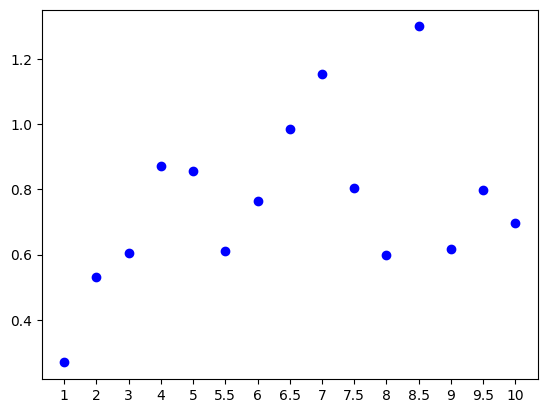

In [65]:
def x(V, mx):
    return (2 * 1064 / np.pi) * np.arccos(-V / mx)
for i in range(len(amps)):
    # d_amp = np.abs(x(Vs[i][find_idx(amps[i], np.max(np.abs(amps[i])))] + np.sqrt(2 * (f[1] - f[0]) * data_psds[i][find_idx(amps[i], np.max(np.abs(amps[i])))]), As[i], Vmins[i]) - x(Vs[i][find_idx(amps[i], np.max(np.abs(amps[i])))], As[i], Vmins[i]))
    # fit_amp = np.abs(x(Vs[i][find_idx(amps[i], np.max(np.abs(amps[i])))] + np.max(np.abs(amps[i])), As[i], Vmins[i]) - x(Vs[i][find_idx(amps[i], np.max(np.abs(amps[i])))] - np.max(np.abs(amps[i])), As[i], Vmins[i]))
    # c_amp = np.abs(x(Vs[i][find_idx(amps[i], np.max(np.abs(amps[i])))] + np.sqrt(2 * (f[1] - f[0]) * calc_psds[i][find_idx(amps[i], np.max(np.abs(amps[i])))]), As[i], Vmins[i]) - x(Vs[i][find_idx(amps[i], np.max(np.abs(amps[i])))], As[i], Vmins[i]))
    d_amp = np.abs(x(Vs[i][find_idx(amps[i], np.max(np.abs(amps[i])))] + np.sqrt(2 * (f[1] - f[0]) * data_psds[i][find_idx(amps[i], np.max(np.abs(amps[i])))]),Vmaxes[i]) - x(Vs[i][find_idx(amps[i], np.max(np.abs(amps[i])))], Vmaxes[i]))
    plt.scatter(voltages[i], d_amp, c = "blue")
    # plt.scatter(i, fit_amp, c = "red")
    # plt.scatter(i, c_amp, c = "yellow")

../../data/20261006/2nd/piezo_char_10V_109kHz_calibration/iter_2.tdms
2.6276259938172757


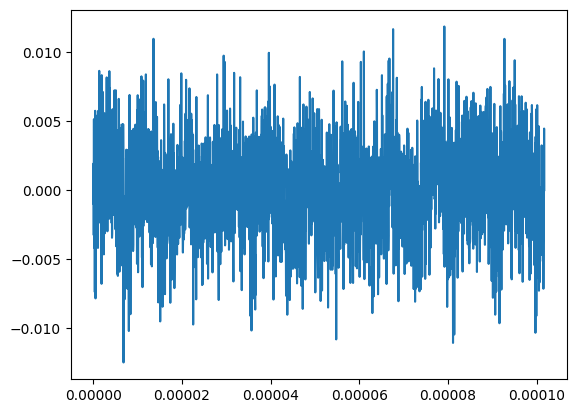

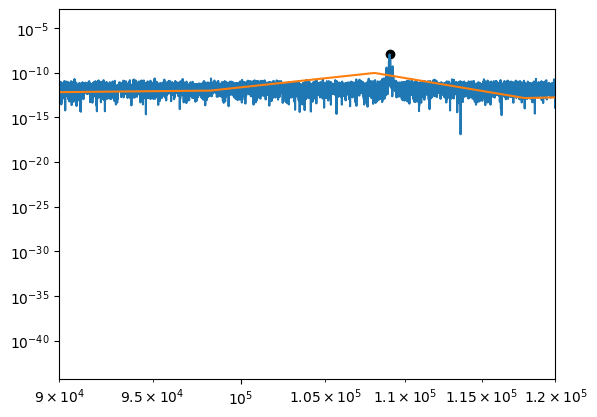

In [42]:
voltages = ["1", "2", "3", "4", "5", "5.5", "6", "6.5", "7", "7.5", "8", "8.5", "9", "9.5", "10"]
freq = 109e3
def x(V, A, mn):
    return (2 * 1064 / np.pi) * np.arccos(np.sqrt(np.abs(V - mn) / A))
# def transform(x, factor):
#     return 2 * (1064e-9 / 2 / np.pi)* np.arccos(-x / factor)
# disps = []
# for v in range(len(voltages)):
#     cals = System("michelson", ["../../data/20261006/2nd/piezo_char_" + voltages[v] + "V_109kHz_calibration/iter_" + str(i) + ".tdms" for i in range(0, 3)], set_data = True, channel = "X")
#     disp = []
#     for i, d in enumerate(cals.get_data()):
#         f, x = periodogram(transform(d.collection[0].x, np.max(d.collection[0].x)), d.r)
#         disp.append(np.sqrt(x[find_idx(f, find_nearest(f, freq))] * 109e3))
#     disps.append(np.mean(disp))
# plt.plot(np.array(voltages, dtype = float), np.array(disps) * 1e9, "o-")
cals = System("michelson", ["../../data/20261006/2nd/piezo_char_" + voltages[v] + "V_109kHz_calibration/iter_" + str(i) + ".tdms" for v in range(len(voltages)) for i in range(0, 3)], set_data = True, channel = "X")
idx = 44
mn = min(cals.get_data()[idx].collection[0].x)
mx = max(cals.get_data()[idx].collection[0].x)
# plt.plot(cals.get_data()[0].collection[0].t, cals.get_data()[0].collection[0].x)
# idx = find_idx(cals.get_data()[0].collection[0].x[9306:], find_nearest(cals.get_data()[0].collection[0].x[9306:], (np.max(cals.get_data()[0].collection[0].x) - np.min(cals.get_data()[0].collection[0].x)) / 2)) + 9305
# plt.scatter(cals.get_data()[0].collection[0].t[idx], cals.get_data()[0].collection[0].x[idx], c = "k")
# plt.show()

print(cals.get_df()[idx])

f, p = periodogram(cals.get_data()[idx].collection[0].x, cals.get_data()[idx].r)
A = mx - mn
a = np.sqrt(2 * (f[1] - f[0]) * p[find_idx(f, find_nearest(f, 109e3))])
print(x(np.mean(cals.get_data()[idx].collection[0].x) - a, A, mn) - x(np.mean(cals.get_data()[idx].collection[0].x), A, mn))
cals.get_data()[idx].apply("time_gate", tmin = cals.get_data()[idx].collection[0].t[idx] - 1e-4, tmax = cals.get_data()[idx].collection[0].t[idx] + 1e-4, inplace = True)
cals.get_data()[idx].apply("detrend", mode = "linear", inplace = True)
plt.plot(cals.get_data()[idx].collection[0].t, cals.get_data()[idx].collection[0].x)
plt.show()

plt.loglog(f, p)
plt.scatter(109e3, p[find_idx(f, find_nearest(f, 109e3))], c = "k")
f, p = periodogram(cals.get_data()[idx].collection[0].x, cals.get_data()[idx].r)
plt.loglog(f, p)
plt.xlim(9e4, 1.2e5)
plt.show()

In [56]:
from analysis import mic_correct
mic = System("mic", [f"../../data/20261008/{i if i % 1 != 0 else int(i)}Vpp/iter_{j}.tdms" for i in np.linspace(0.5, 10, 20) for j in range(0, 5)], set_data = True, channel = "X")

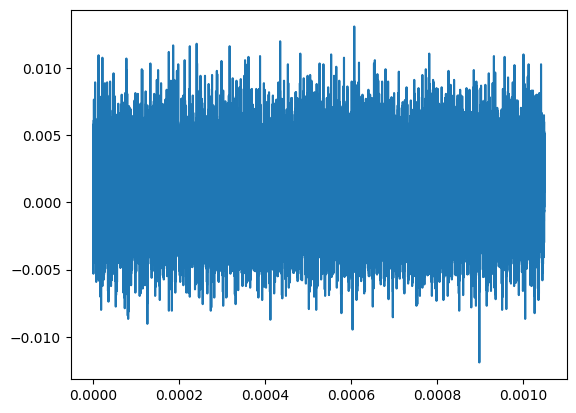

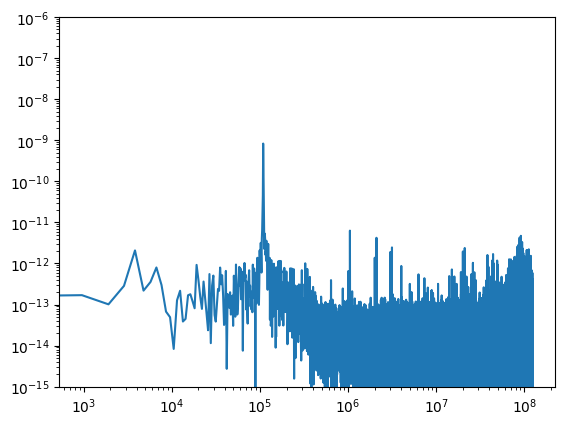

2.559839826933391


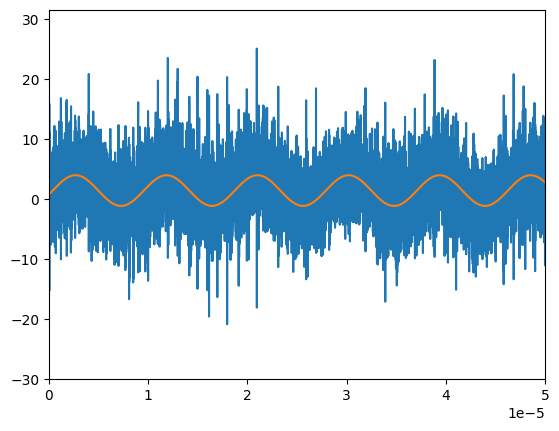

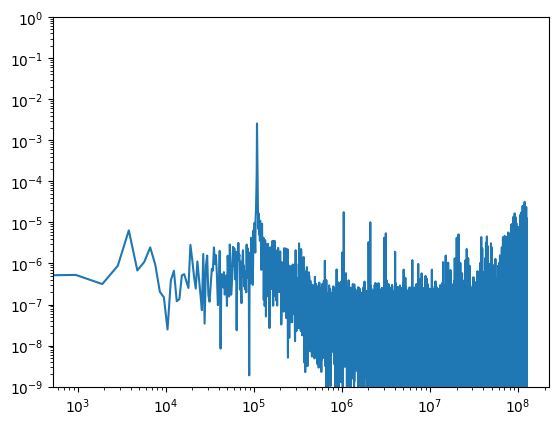

In [85]:
idx = 40

plt.plot(mic.get_data()[idx].collection[0].t, mic.get_data()[idx].collection[0].x)
plt.show()

f, p = periodogram(mic.get_data()[idx].collection[0].x, mic.get_data()[idx].r)
plt.loglog(f, p)
plt.ylim(1e-15, 1e-6)
plt.show()

plt.plot(mic.get_data()[idx].collection[0].t, mic_correct(mic.get_data()[idx].collection[0]))
popt, pcov = fit(wave, mic.get_data()[idx].collection[0].t, mic_correct(mic.get_data()[idx].collection[0]), p0 = [10, 0, 0])
print(popt[0])
plt.plot(mic.get_data()[idx].collection[0].t, wave(mic.get_data()[idx].collection[0].t, *popt))
plt.xlim(0, 5e-5)
plt.show()

f, p = periodogram(mic_correct(mic.get_data()[idx].collection[0]), mic.get_data()[idx].r)
plt.loglog(f, p)
plt.ylim(1e-9, 1)
plt.show()

In [86]:
2.5 / 1.208 / (2 * np.pi * 109e3) / 343

8.809932644048158e-09

Bad pipe message: %s [b'\x8b\xde\xbb\xf5\x80Z\xb0\xf8#S\xe2|\x97\xf0@\x8e-\x92\x00\x01', b'\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86']
Bad pipe message: %s [b'"[o\x94o\xcdu\xb4\x1d3\xce7A\tH\x92\xa2c\x00\x01|\x00\x00\x00\x01\x00\x02\x00\x03\x00\x04\x00\x05\x00\x06\x00\x07\x00\x08\x00\t\x00\n\x00\x0b\x00\x0c\x00\r\x00\x0e\x00\x0f\x00\x10\x00\x11\x00\x12\x00\x13\x00\x14\x00\x15\x00\x16\x00\x17\x00\x18\x00\x19\x00\x1a\x00\x1b\x00/\x000\x001\x002\x003\x004\x005\x006\x007\x008\x009\x00:\x00;\x00<\x00=\x00>\x00?\x00@\x00A\x00B\x00C\x00D\x00E\x00F\x00g\x00h\x00i\x00j\x00k\x00l\x00m\x00\x84\x00\x85\x00\x86\x00\x87\x00\x88\x00\x89\x00\x96\x00\x97\x0

In [1]:
import numpy as np
import sys
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit as fit
from scipy.signal import periodogram, hilbert
sys.path.append("../")
from analysis import System

def wave(t, A, phi, offset):
    return np.abs(A) * np.sin(109e3 * 2 * np.pi * t - phi) + offset
def interference(x, A, offset):
    return np.abs(A) * np.power(np.cos(x * np.pi / 2 / 1064e-9), 2) + offset
def find_nearest(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return array[idx]
def find_idx(array, value):
    array = np.asarray(array)
    idx = (np.abs(array - value)).argmin()
    return idx

voltages = ["1", "2", "3", "4", "5", "5.5", "6", "6.5", "7", "7.5", "8", "8.5", "9", "9.5", "10"]
cals = System("michelson", ["../../data/20261006/2nd/piezo_char_" + voltages[v] + "V_109kHz_calibration/iter_" + str(i) + ".tdms" for v in range(len(voltages)) for i in range(0, 3)], set_data = True, channel = "X")

In [3]:
freq = 109e3
fig, ax = plt.subplots(3, 15, figsize = (50, 12))
for i, d in enumerate(cals.get_data()):
    cals.set_data(ind = i)
    d.apply("filter", cutoff = [104e3, 114e3], btype = "bandpass", inplace = True)
    d.apply("detrend", mode = "linear", inplace = True)
    ax[i % 3][i // 3].plot(d.collection[0].t, d.collection[0].x)
    ax[i % 3][i // 3].plot(d.collection[1].t, d.collection[1].x)
plt.tight_layout()
fig.savefig("timetraces.png")
plt.close()

In [3]:
freq = 109e3
fig, ax = plt.subplots(3, 15, figsize = (50, 12))
for i, d in enumerate(cals.get_data()):
    cals.set_data(ind = i)
    d.apply("filter", cutoff = [104e3, 114e3], btype = "bandpass", inplace = True)
    d.apply("detrend", mode = "linear", inplace = True)
    f, p = periodogram(d.collection[0].x, d.r)
    ax[i % 3][i // 3].loglog(f, p)
    _, p = periodogram(d.collection[1].x, d.r)
    ax[i % 3][i // 3].loglog(f, p)
plt.tight_layout()
fig.savefig("psds.png")
plt.close()

In [3]:
for i in range(0, 15):
    r = .5e3
    st = i * 3
    idx = st
    col = 0
    fig, ax = plt.subplots(2, 6, figsize = (30, 10))
    cals.set_data(ind = idx)
    cals.get_data()[idx].apply("filter", cutoff = [109e3 - r, 109e3 + r], btype = "bandpass", inplace = True)
    cals.get_data()[idx].apply("detrend", mode = "linear", inplace = True)
    sig = hilbert(cals.get_data()[idx].collection[col].x)
    env = np.abs(sig)
    ax[0][0].plot(cals.get_data()[idx].collection[col].t, cals.get_data()[idx].collection[col].x)
    ax[0][0].plot(cals.get_data()[idx].collection[col].t, env)
    hist, bins = np.histogram(env, bins = 100)
    ax[1][0].stairs(hist, bins)
    
    sig = hilbert(cals.get_data()[idx].collection[col + 1].x)
    env = np.abs(sig)
    ax[0][1].plot(cals.get_data()[idx].collection[col + 1].t, cals.get_data()[idx].collection[col + 1].x)
    ax[0][1].plot(cals.get_data()[idx].collection[col + 1].t, env)
    hist, bins = np.histogram(env, bins = 100)
    ax[1][1].stairs(hist, bins)
    
    idx = st + 1
    cals.set_data(ind = idx)
    cals.get_data()[idx].apply("filter", cutoff = [109e3 - r, 109e3 + r], btype = "bandpass", inplace = True)
    cals.get_data()[idx].apply("detrend", mode = "linear", inplace = True)
    sig = hilbert(cals.get_data()[idx].collection[col].x)
    env = np.abs(sig)
    ax[0][2].plot(cals.get_data()[idx].collection[col].t, cals.get_data()[idx].collection[col].x)
    ax[0][2].plot(cals.get_data()[idx].collection[col].t, env)
    hist, bins = np.histogram(env, bins = 100)
    ax[1][2].stairs(hist, bins)
    
    sig = hilbert(cals.get_data()[idx].collection[col + 1].x)
    env = np.abs(sig)
    ax[0][3].plot(cals.get_data()[idx].collection[col + 1].t, cals.get_data()[idx].collection[col + 1].x)
    ax[0][3].plot(cals.get_data()[idx].collection[col + 1].t, env)
    hist, bins = np.histogram(env, bins = 100)
    ax[1][3].stairs(hist, bins)
    
    idx = st + 2
    cals.set_data(ind = idx)
    cals.get_data()[idx].apply("filter", cutoff = [109e3 - r, 109e3 + r], btype = "bandpass", inplace = True)
    cals.get_data()[idx].apply("detrend", mode = "linear", inplace = True)
    sig = hilbert(cals.get_data()[idx].collection[col].x)
    env = np.abs(sig)
    ax[0][4].plot(cals.get_data()[idx].collection[col].t, cals.get_data()[idx].collection[col].x)
    ax[0][4].plot(cals.get_data()[idx].collection[col].t, env)
    hist, bins = np.histogram(env, bins = 100)
    ax[1][4].stairs(hist, bins)
    
    sig = hilbert(cals.get_data()[idx].collection[col + 1].x)
    env = np.abs(sig)
    ax[0][5].plot(cals.get_data()[idx].collection[col + 1].t, cals.get_data()[idx].collection[col + 1].x)
    ax[0][5].plot(cals.get_data()[idx].collection[col + 1].t, env)
    hist, bins = np.histogram(env, bins = 100)
    ax[1][5].stairs(hist, bins)
    
    fig.suptitle(f"Calibration Scan with Piezo Driven at {voltages[int(st / 3)]} Vpp")
    ax[0][0].set_xlabel("Time, t (s)")
    ax[0][0].set_ylabel("Volts, v (V)")
    ax[1][0].set_xlabel("Volts, v (V)")
    ax[1][0].set_ylabel("Count")
    plt.tight_layout()
    fig.savefig(f"{voltages[i]}Vpp.png")
    plt.close()